In [1]:
import os
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.messages import HumanMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import MessagesState
from IPython.display import Image, display
from dotenv import load_dotenv
from pypdf import PdfReader
from typing import List, Dict

In [2]:
load_dotenv()

True

In [3]:
model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [4]:
embeddings_fn = OpenAIEmbeddings(model="text-embedding-3-large")

In [5]:
vector_store = Chroma(
    collection_name="rag_knowledge_base_demo",
    embedding_function=embeddings_fn,
    persist_directory="./chroma_langchain_db",
)

In [6]:
file_path = "data/exam_guide.pdf"

reader = PdfReader(file_path)

docs: list[Document] = []

for page in reader.pages:
    source = f"{file_path}"
    docs.append(Document(page_content=page.extract_text(), metadata={"source": source}))

print(f"Loaded {len(docs)} documentation pages.\n\n")

print(docs)

Loaded 3 documentation pages.


[Document(metadata={'source': 'data/exam_guide.pdf'}, page_content='CERTIFICATION · EXAM GUIDE\nLangChain Certified Agent Engineer\nExam guide: format, rules, and what each section covers.\nARRIVE EARLY\nPlease join your exam session at least 15 minutes before your scheduled start time. This window is used for ID check, room scan, and\nsystem veriﬁcation with your proctor.\nIf you join more than 10 minutes after your scheduled start time you will be marked as a no-show and will need to reschedule the\nexam at full cost.\nThis is a 2-hour exam taken solo and proctored, with a dedicated LangSmith organization provisioned for you. It is structured around the\nAgent Development Lifecycle (ADLC). The exam is semi-open-book: you may consult a small set of LangChain-owned resources, but\nno general search, AI assistants, or second screens.\nExam-day logistics\nYou will receive two invites in relation to this exam. The ﬁrst will be an invite to take the test its

In [7]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
all_splits = text_splitter.split_documents(docs)

print(f"Split documentation into {len(all_splits)} chunks.")

Split documentation into 8 chunks.


In [8]:
vector_store.add_documents(documents=all_splits)

print(f"Indexed {len(all_splits)} chunks.")

Indexed 8 chunks.


In [9]:
class State(MessagesState):
    question: str
    answer: str
    documents: List[Document]

In [10]:
def retrieve(state: State):
    question = state["question"]
    retrieved_docs = vector_store.similarity_search(question)
    return {"documents": retrieved_docs}

In [11]:
def augment(state: State):
    question = state["question"]
    documents = state["documents"]
    docs_content = "\n\n".join(doc.page_content for doc in documents)

    template = ChatPromptTemplate(
        [
            ("system", "You are an assistant for question-answering tasks."),
            (
                "human",
                """Use the following pieces of retrieved context to answer the question. 
                If you don't know the answer, just say that you don't know.  
                Use three sentences maximum and keep the answer concise. 
                \n# Question: \n-> {question} 
                \n# Context: \n-> {context} 
                \n# Answer: """,
            ),
        ]
    )

    messages = template.invoke(
        {"context": docs_content, "question": question}
    ).to_messages()

    return {"messages": messages}

In [12]:
def generate(state: State):
    ai_message = llm.invoke(state["messages"])
    return {"answer": ai_message.content, "messages": ai_message}

In [13]:
workflow = StateGraph(State)

workflow.add_node("retrieve", retrieve)
workflow.add_node("augment", augment)
workflow.add_node("generate", generate)

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "augment")
workflow.add_edge("augment", "generate")
workflow.add_edge("generate", END)

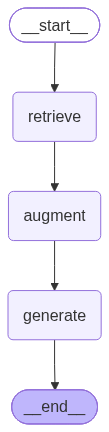

In [14]:
graph = workflow.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
output = graph.invoke({"question": "What are Open source models?"})

In [16]:
output["answer"]

[{'type': 'text',
  'text': 'Open-source models are AI models whose code—and sometimes architecture, weights, and training details—is publicly available for people to inspect, modify, and distribute under a specified license. The provided context does not specifically discuss them.',
  'annotations': [],
  'id': 'msg_08e95d134cad4661006af48e3f2a7487d289444418b67a8228',
  'phase': 'final_answer'}]

In [17]:
for message in output["messages"]:
    message.pretty_print()

================================ System Message ================================

You are an assistant for question-answering tasks.
================================ Human Message =================================

Use the following pieces of retrieved context to answer the question. 
                If you don't know the answer, just say that you don't know.  
                Use three sentences maximum and keep the answer concise. 
                
# Question: 
-> What are Open source models? 
                
# Context: 
-> SECTION BREAKDOWN
Section Breakdown
What each section covers, recommended courses, and areas worth focusing on.
1 · Build 10 questions · 25% of score
Designing agents with create_agent  and deepagents , and shaping the context they operate in.
COURSES LangChain Foundations · Deep Agents Foundations
FOCUS AREAS
Differences between create_agent  and deepagents .
Middleware.
Context engineering for long-running agents.
AGENTS.md  and SKILL.md .
Sandboxing.
2 · Test 

In [18]:
output = graph.invoke(
    input={"question": "What is The Langchain exam main requirement?"},
)

In [19]:
output["answer"]

[{'type': 'text',
  'text': 'The main requirement is to take the two-hour exam solo under live proctoring, with webcam, phone environment camera, and primary-screen sharing enabled. Only whitelisted LangChain resources are allowed; AI tools, web searches, second screens, and outside communication are prohibited.',
  'annotations': [],
  'id': 'msg_0aae78e894a0a59e006af48e41ac9087d28a14a931c8225c72',
  'phase': 'final_answer'}]

In [20]:
for message in output["messages"]:
    message.pretty_print()

================================ System Message ================================

You are an assistant for question-answering tasks.
================================ Human Message =================================

Use the following pieces of retrieved context to answer the question. 
                If you don't know the answer, just say that you don't know.  
                Use three sentences maximum and keep the answer concise. 
                
# Question: 
-> What is The Langchain exam main requirement? 
                
# Context: 
-> CERTIFICATION · EXAM GUIDE
LangChain Certified Agent Engineer
Exam guide: format, rules, and what each section covers.
ARRIVE EARLY
Please join your exam session at least 15 minutes before your scheduled start time. This window is used for ID check, room scan, and
system veriﬁcation with your proctor.
If you join more than 10 minutes after your scheduled start time you will be marked as a no-show and will need to reschedule the
exam at full cost.
